# HR Workforce Analytics - Data Cleaning & EDA

In this notebook I clean the 4 HR files, merge them into one table and explore what is driving employee attrition.
The cleaned files are saved in `clean_data/` and are used for the SQL queries and the Power BI dashboard.

**Steps**
1. Load data and check data quality
2. Clean the employee table (dates, attrition flag, age, tenure)
3. Clean the recruitment table
4. Basic stats and EDA charts
5. Attrition drivers (survey scores, training, job title, hiring trend)
6. Key findings
7. (Optional) Load the cleaned tables into SQL Server

> Run this notebook from inside the `eda/` folder. All paths are relative.

# Section 1 - Data Loading & Cleaning

In [1]:
import os
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import chi2_contingency, ttest_ind

warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', 50)

In [2]:
# folder paths (relative to this notebook)
RAW_DIR = '../raw_data'
CLEAN_DIR = '../clean_data'
CHART_DIR = '../charts'

os.makedirs(CLEAN_DIR, exist_ok=True)
os.makedirs(CHART_DIR, exist_ok=True)

emp = pd.read_csv(os.path.join(RAW_DIR, 'employee_data.csv'), encoding='utf-8-sig')
survey = pd.read_csv(os.path.join(RAW_DIR, 'employee_engagement_survey_data.csv'))
training = pd.read_csv(os.path.join(RAW_DIR, 'training_and_development_data.csv'))
recruit = pd.read_csv(os.path.join(RAW_DIR, 'recruitment_data.csv'))

print('Employee data   :', emp.shape)
print('Survey data     :', survey.shape)
print('Training data   :', training.shape)
print('Recruitment data:', recruit.shape)

Employee data   : (3000, 26)
Survey data     : (3000, 5)
Training data   : (3000, 9)
Recruitment data: (3000, 18)


In [3]:
# Rename join keys to match
survey.rename(columns={'Employee ID': 'EmpID'}, inplace=True)
training.rename(columns={'Employee ID': 'EmpID'}, inplace=True)

### 1.1 Data quality checks
Before cleaning anything I want to know about duplicates, missing values and how the dates are stored.

In [4]:
for name, data in [('employee', emp), ('survey', survey), ('training', training), ('recruitment', recruit)]:
    print(f"{name:12} rows = {len(data)}   duplicate rows = {data.duplicated().sum()}   missing values = {data.isnull().sum().sum()}")

print('\nDuplicate EmpIDs in employee table:', emp['EmpID'].duplicated().sum())
print('\nColumns with missing values (employee table):')
print(emp.isnull().sum()[emp.isnull().sum() > 0])

employee     rows = 3000   duplicate rows = 0   missing values = 2934
survey       rows = 3000   duplicate rows = 0   missing values = 0
training     rows = 3000   duplicate rows = 0   missing values = 0
recruitment  rows = 3000   duplicate rows = 0   missing values = 0

Duplicate EmpIDs in employee table: 0

Columns with missing values (employee table):
ExitDate                  1467
TerminationDescription    1467
dtype: int64


In [5]:
# checking text values and date formats
print(emp['DepartmentType'].unique())
print(emp[['StartDate', 'ExitDate', 'DOB']].dropna().head(3))
print(survey['Survey Date'].head(3).tolist(), training['Training Date'].head(3).tolist())

<StringArray>
[   'Production       ',                'Sales',                'IT/IS',
     'Executive Office', 'Software Engineering',        'Admin Offices']
Length: 6, dtype: str
   StartDate   ExitDate         DOB
6  06-Apr-22  03-Jul-23  01-07-1942
7  06-Nov-20  29-Jan-23  07-03-1957
9  21-Jan-22  29-Jun-23  11-11-1949
['10-10-2022', '03-08-2023', '03-01-2023'] ['21-Sep-22', '19-Jul-23', '24-Feb-23']


**What I found**
- No duplicate rows and every EmpID is unique.
- `ExitDate` and `TerminationDescription` are empty for 1467 rows. That is expected because those people have not left.
- `DepartmentType` has extra spaces at the end of `Production`, so a group by would treat it as a different value.
- Dates are in mixed formats: `StartDate` / `ExitDate` look like `20-Sep-19` while `DOB` and `Survey Date` are day-first like `07-10-1969`. I will give the exact format to `pd.to_datetime` instead of letting pandas guess.

### 1.2 Clean the employee table

In [6]:
emp.drop_duplicates(inplace=True)

# remove extra spaces from all text columns
for col in emp.columns:
    if pd.api.types.is_string_dtype(emp[col]):
        emp[col] = emp[col].str.strip()

# convert dates using the exact format of each column
emp['StartDate'] = pd.to_datetime(emp['StartDate'], format='%d-%b-%y', errors='coerce')
emp['ExitDate'] = pd.to_datetime(emp['ExitDate'], format='%d-%b-%y', errors='coerce')
emp['DOB'] = pd.to_datetime(emp['DOB'], format='%d-%m-%Y', errors='coerce')
survey['Survey Date'] = pd.to_datetime(survey['Survey Date'], format='%d-%m-%Y', errors='coerce')
training['Training Date'] = pd.to_datetime(training['Training Date'], format='%d-%b-%y', errors='coerce')

print('Dates that failed to convert:')
print(emp[['StartDate', 'ExitDate', 'DOB']].isnull().sum())
print(emp['DepartmentType'].unique())

Dates that failed to convert:


StartDate       0
ExitDate     1467
DOB             0
dtype: int64
<StringArray>
[          'Production',                'Sales',                'IT/IS',
     'Executive Office', 'Software Engineering',        'Admin Offices']
Length: 6, dtype: str


**Attrition flag**

In my first version I made the flag from `TerminationType` (anything other than `Unk` = left). The table below shows why that was wrong:
`TerminationType` is filled even for many **Active** employees, so it was counting about half of the company as "left".
`EmployeeStatus` is the reliable column, so only `Voluntarily Terminated` and `Terminated for Cause` are counted as attrition.

In [7]:
pd.crosstab(emp['EmployeeStatus'], emp['TerminationType'])

TerminationType,Involuntary,Resignation,Retirement,Unk,Voluntary
EmployeeStatus,,,,,
Active,244,252,244,1467,251
Future Start,18,11,23,0,17
Leave of Absence,19,21,24,0,22
Terminated for Cause,21,22,10,0,13
Voluntarily Terminated,86,74,76,0,85


In [8]:
left_status = ['Voluntarily Terminated', 'Terminated for Cause']
emp['Attrition_Flag'] = emp['EmployeeStatus'].isin(left_status).astype(int)

print(emp['Attrition_Flag'].value_counts())
print('Attrition Rate:', round(emp['Attrition_Flag'].mean() * 100, 2), '%')

Attrition_Flag
0    2613
1     387
Name: count, dtype: int64
Attrition Rate: 12.9 %


**Age and tenure**

Earlier I calculated age and tenure from *today's* date. That had two problems:
1. The numbers change every time the notebook is run.
2. People who already left kept getting more tenure, so the tenure vs attrition chart was wrong.

Now I use a fixed snapshot date (the last date in the employee data). For employees who left, tenure is counted only till their `ExitDate`.
I also noticed that some *active* employees have an `ExitDate` filled in, so `ExitDate` is used only for leavers.

In [9]:
# last date available in the employee data
snapshot_date = max(emp['StartDate'].max(), emp['ExitDate'].max())
print('Snapshot date:', snapshot_date.date())

active_with_exit = ((emp['Attrition_Flag'] == 0) & emp['ExitDate'].notnull()).sum()
print('Active employees that still have an ExitDate:', active_with_exit)

# leavers -> ExitDate, everyone else -> snapshot date
end_date = emp['ExitDate'].where(emp['Attrition_Flag'] == 1, snapshot_date)

emp['Tenure_Years'] = ((end_date - emp['StartDate']).dt.days / 365.25).round(1)
emp['Age'] = ((snapshot_date - emp['DOB']).dt.days / 365.25).astype(int)

emp[['Age', 'Tenure_Years']].describe()

Snapshot date: 2023-08-06
Active employees that still have an ExitDate: 1146


,Age,Tenure_Years
count,3000.000000,3000.000000
mean,51.400333,2.350300
std,17.689838,1.455424
min,22.000000,0.000000
25%,35.000000,1.100000
50%,51.000000,2.300000
75%,67.000000,3.600000
max,81.000000,5.000000


In [10]:
# old bins were [20,30,40,50,70] so everyone older than 70 became NaN (707 employees were missing from the age charts)
emp['Age_Group'] = pd.cut(emp['Age'],
    bins=[17, 30, 40, 50, 60, 100],
    labels=['18-30', '31-40', '41-50', '51-60', '60+'])

emp['Tenure_Band'] = pd.cut(emp['Tenure_Years'],
    bins=[0, 1, 2, 3, 4, 100], right=False,
    labels=['<1 yr', '1-2 yrs', '2-3 yrs', '3-4 yrs', '4+ yrs'])

print(emp['Age_Group'].value_counts(dropna=False).sort_index())
print()
print(emp['Tenure_Band'].value_counts(dropna=False).sort_index())

Age_Group
18-30     489
31-40     486
41-50     489
51-60     458
60+      1078
Name: count, dtype: int64

Tenure_Band
<1 yr      668
1-2 yrs    625
2-3 yrs    605
3-4 yrs    541
4+ yrs     561
Name: count, dtype: int64


In [11]:
# Merge employee + survey + training (one row per employee)
df = emp.merge(survey, on='EmpID', how='left')
df = df.merge(training, on='EmpID', how='left')

print('Merged shape:', df.shape)
print('Employees without a survey   :', df['Engagement Score'].isnull().sum())
print('Employees without a training :', df['Training Outcome'].isnull().sum())

Merged shape: (3000, 43)
Employees without a survey   : 0
Employees without a training : 0


In [12]:
df.head()

,EmpID,FirstName,LastName,StartDate,ExitDate,Title,Supervisor,ADEmail,BusinessUnit,EmployeeStatus,EmployeeType,PayZone,EmployeeClassificationType,TerminationType,TerminationDescription,DepartmentType,Division,DOB,State,JobFunctionDescription,GenderCode,LocationCode,RaceDesc,MaritalDesc,Performance Score,Current Employee Rating,Attrition_Flag,Tenure_Years,Age,Age_Group,Tenure_Band,Survey Date,Engagement Score,Satisfaction Score,Work-Life Balance Score,Training Date,Training Program Name,Training Type,Training Outcome,Location,Trainer,Training Duration(Days),Training Cost
0,3427,Uriah,Bridges,2019-09-20,NaT,Production Technician I,Peter Oneill,uriah.bridges@bilearner.com,CCDR,Active,Contract,Zone C,Temporary,Unk,NaN,Production,Finance & Accounting,1969-10-07,MA,Accounting,Female,34904,White,Widowed,Fully Meets,4,0,3.9,53,51-60,3-4 yrs,2023-01-14,1,2,3,2023-07-15,Leadership Development,Internal,Failed,South Marisa,Taylor Rodriguez,2,606.11
1,3428,Paula,Small,2023-02-11,NaT,Production Technician I,Renee Mccormick,paula.small@bilearner.com,EW,Active,Contract,Zone A,Part-Time,Unk,NaN,Production,Aerial,1965-08-30,MA,Labor,Male,6593,Hispanic,Widowed,Fully Meets,3,0,0.5,57,51-60,<1 yr,2022-09-09,2,1,5,2022-09-12,Customer Service,External,Incomplete,Tammieville,Kelly Patterson DDS,4,673.02
2,3429,Edward,Buck,2018-12-10,NaT,Area Sales Manager,Crystal Walker,edward.buck@bilearner.com,PL,Active,Full-Time,Zone B,Part-Time,Unk,NaN,Sales,General - Sga,1991-10-06,MA,Assistant,Male,2330,Hispanic,Widowed,Fully Meets,4,0,4.7,31,31-40,4+ yrs,2023-05-27,1,2,1,2022-08-13,Leadership Development,External,Failed,East Roberthaven,Taylor Thomas,2,413.28
3,3430,Michael,Riordan,2021-06-21,NaT,Area Sales Manager,Rebekah Wright,michael.riordan@bilearner.com,CCDR,Active,Contract,Zone A,Full-Time,Unk,NaN,Sales,Finance & Accounting,1998-04-04,ND,Clerk,Male,58782,Other,Single,Fully Meets,2,0,2.1,25,18-30,2-3 yrs,2023-06-16,5,5,4,2022-12-15,Project Management,External,Completed,Garzatown,Holly Elliott,3,663.78
4,3431,Jasmine,Onque,2019-06-29,NaT,Area Sales Manager,Jason Kim,jasmine.onque@bilearner.com,TNS,Active,Contract,Zone A,Temporary,Unk,NaN,Sales,General - Con,1969-08-29,FL,Laborer,Female,33174,Other,Married,Fully Meets,3,0,4.1,53,51-60,4+ yrs,2022-11-25,2,5,3,2023-07-13,Technical Skills,External,Failed,Lake Meganville,Donald Martinez,5,399.03


### 1.3 Clean the recruitment table
In the first version I exported this file without any changes. Now I convert the dates, add the applicant age
and drop the personal contact columns (phone, email, address) because they are not needed for the analysis.

In [13]:
for col in recruit.columns:
    if pd.api.types.is_string_dtype(recruit[col]):
        recruit[col] = recruit[col].str.strip()

recruit['Application Date'] = pd.to_datetime(recruit['Application Date'], format='%d-%b-%y', errors='coerce')
recruit['Date of Birth'] = pd.to_datetime(recruit['Date of Birth'], format='%d-%m-%Y', errors='coerce')
recruit['Applicant_Age'] = ((recruit['Application Date'] - recruit['Date of Birth']).dt.days / 365.25).astype(int)

recruit = recruit.drop(columns=['Phone Number', 'Email', 'Address', 'Zip Code'])

print(recruit.isnull().sum().sum(), 'missing values')
print('Application dates from', recruit['Application Date'].min().date(), 'to', recruit['Application Date'].max().date())
recruit.head()

0 missing values
Application dates from 2023-05-06 to 2023-08-05


,Applicant ID,Application Date,First Name,Last Name,Gender,Date of Birth,City,State,Country,Education Level,Years of Experience,Desired Salary,Job Title,Status,Applicant_Age
0,1001,2023-06-03,Scott,Sheppard,Male,1992-08-31,Hollandfort,NV,Micronesia,High School,8,60103.21,Chief Technology Officer,Interviewing,30
1,1002,2023-05-15,Stanley,Lewis,Male,1965-04-29,Port Margaretfurt,TN,Greenland,Bachelor's Degree,17,64575.84,"Designer, furniture",Rejected,58
2,1003,2023-08-04,Javier,Li,Female,1973-03-10,Dianaland,TX,China,PhD,20,39422.71,"Sound technician, broadcasting/film/video",Rejected,50
3,1004,2023-07-28,Christopher,Johnston,Other,2001-04-04,Youngfurt,GA,Ghana,High School,8,51045.11,Air cabin crew,Rejected,22
4,1005,2023-06-05,Melissa,Hicks,Other,1978-06-17,East Ashleyborough,IN,Solomon Islands,Master's Degree,0,52792.86,Art therapist,Interviewing,44


In [14]:
# Export cleaned files (used by the SQL script and Power BI)
df.to_csv(os.path.join(CLEAN_DIR, 'cleaned_hr_data.csv'), index=False)
recruit.to_csv(os.path.join(CLEAN_DIR, 'cleaned_recruitment.csv'), index=False)

print('cleaned_hr_data.csv     ->', df.shape)
print('cleaned_recruitment.csv ->', recruit.shape)

cleaned_hr_data.csv     -> (3000, 43)
cleaned_recruitment.csv -> (3000, 15)


# Section 2 - Basic Stats & Overview

In [15]:
print("=== BASIC STATISTICS (numeric columns) ===")
print(df[['Age', 'Tenure_Years', 'Current Employee Rating', 'Engagement Score',
          'Satisfaction Score', 'Work-Life Balance Score', 'Training Cost']].describe().round(2))

print("\n=== EMPLOYEE STATUS ===")
print(emp['EmployeeStatus'].value_counts())

print("\n=== DEPARTMENT WISE COUNT ===")
print(emp['DepartmentType'].value_counts())

print("\n=== GENDER COUNT ===")
print(emp['GenderCode'].value_counts())

print("\n=== PERFORMANCE SCORE COUNT ===")
print(emp['Performance Score'].value_counts())

print("\n=== TRAINING OUTCOME COUNT ===")
print(training['Training Outcome'].value_counts())

print("\n=== RECRUITMENT STATUS COUNT ===")
print(recruit['Status'].value_counts())

=== BASIC STATISTICS (numeric columns) ===
           Age  Tenure_Years  Current Employee Rating  Engagement Score  \
count  3000.00       3000.00                  3000.00           3000.00   
mean     51.40          2.35                     2.97              2.94   
std      17.69          1.46                     1.02              1.43   
min      22.00          0.00                     1.00              1.00   
25%      35.00          1.10                     2.00              2.00   
50%      51.00          2.30                     3.00              3.00   
75%      67.00          3.60                     3.00              4.00   
max      81.00          5.00                     5.00              5.00   

       Satisfaction Score  Work-Life Balance Score  Training Cost  
count             3000.00                  3000.00        3000.00  
mean                 3.02                     2.99         558.63  
std                  1.41                     1.41         263.22  
min      

# Section 3 - EDA Visualizations
All charts are saved in the `charts/` folder. For attrition I mostly plot the **rate (%)** and not the count,
because departments and groups have very different sizes.

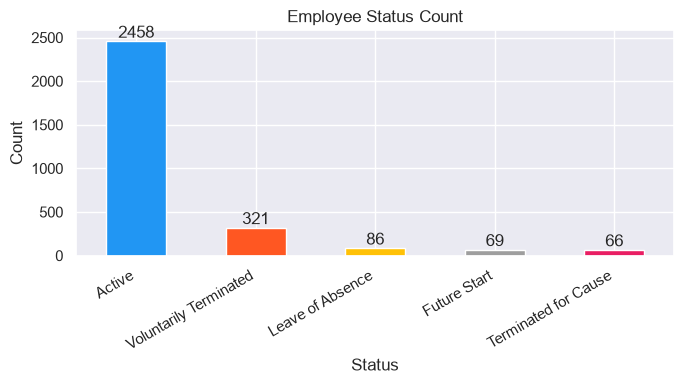

In [16]:
# EMPLOYEE STATUS COUNT
sns.set_theme(style='darkgrid')
status_colors = ['#2196F3', '#FF5722', '#FFC107', '#9E9E9E', '#E91E63']

plt.figure(figsize=(7,4))
ax = emp['EmployeeStatus'].value_counts().plot(kind='bar', color=status_colors)
ax.bar_label(ax.containers[0])
plt.title('Employee Status Count')
plt.xlabel('Status')
plt.ylabel('Count')
plt.xticks(rotation=30, ha='right')
plt.tight_layout()
plt.savefig(os.path.join(CHART_DIR, '1_attrition_count.png'))
plt.show()

### Attrition by department

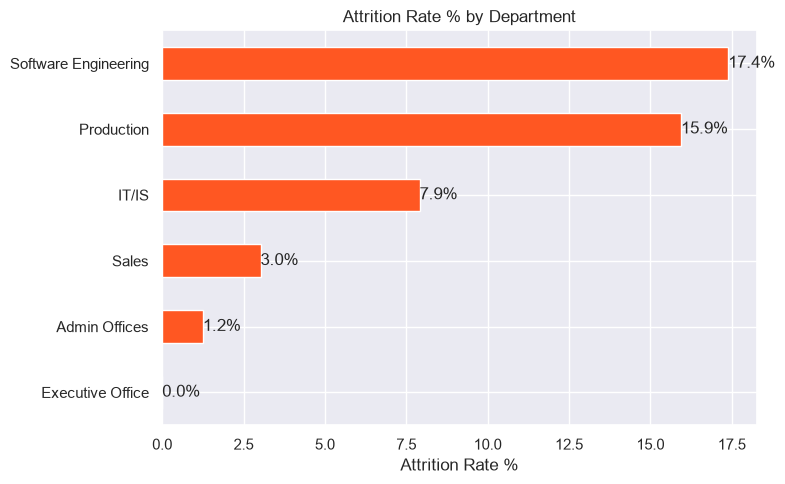

                      count  sum   mean
DepartmentType                         
Software Engineering    115   20  0.174
Production             2020  322  0.159
IT/IS                   430   34  0.079
Sales                   331   10  0.030
Admin Offices            80    1  0.012
Executive Office         24    0  0.000


In [17]:
plt.figure(figsize=(8,5))
dept = emp.groupby('DepartmentType')['Attrition_Flag'].mean() * 100
ax = dept.sort_values().plot(kind='barh', color='#FF5722')
ax.bar_label(ax.containers[0], fmt='%.1f%%')
plt.title('Attrition Rate % by Department')
plt.xlabel('Attrition Rate %')
plt.ylabel('')
plt.tight_layout()
plt.savefig(os.path.join(CHART_DIR, '2_attrition_dept.png'))
plt.show()

# headcount next to the rate, small departments can look extreme
print(emp.groupby('DepartmentType')['Attrition_Flag'].agg(['count', 'sum', 'mean']).sort_values('mean', ascending=False).round(3))

### Attrition by gender

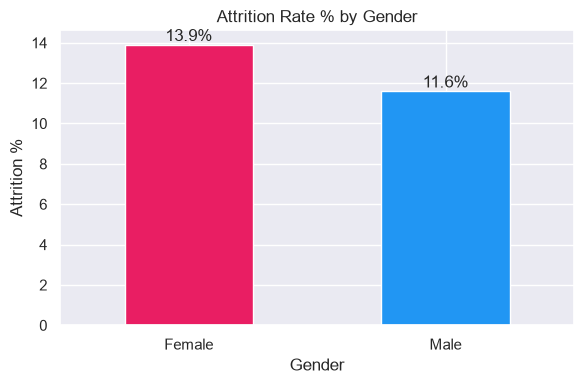

In [18]:
plt.figure(figsize=(6,4))
gender = emp.groupby('GenderCode')['Attrition_Flag'].mean() * 100
ax = gender.plot(kind='bar', color=['#E91E63', '#2196F3'])
ax.bar_label(ax.containers[0], fmt='%.1f%%')
plt.title('Attrition Rate % by Gender')
plt.xlabel('Gender')
plt.ylabel('Attrition %')
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig(os.path.join(CHART_DIR, '3_gender_attrition.png'))
plt.show()

### Attrition by age group

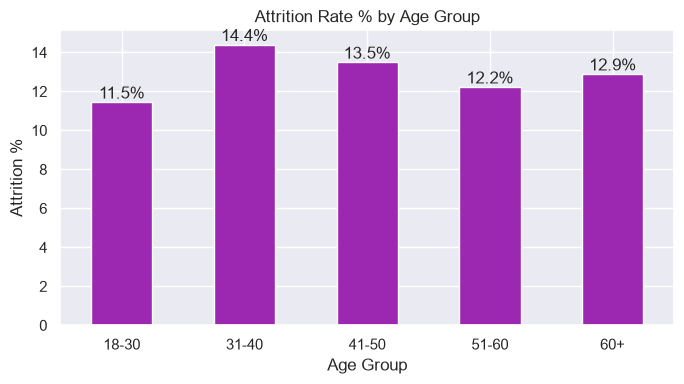

In [19]:
plt.figure(figsize=(7,4))
age_attr = emp.groupby('Age_Group')['Attrition_Flag'].mean() * 100
ax = age_attr.plot(kind='bar', color='#9C27B0')
ax.bar_label(ax.containers[0], fmt='%.1f%%')
plt.title('Attrition Rate % by Age Group')
plt.xlabel('Age Group')
plt.ylabel('Attrition %')
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig(os.path.join(CHART_DIR, '4_age_attrition.png'))
plt.show()

### Performance score

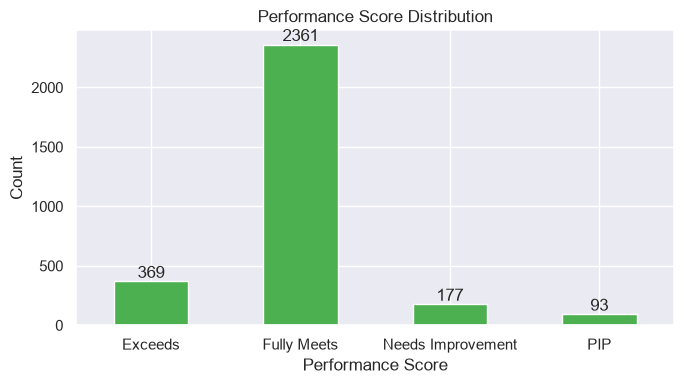

In [20]:
perf_order = ['Exceeds', 'Fully Meets', 'Needs Improvement', 'PIP']

plt.figure(figsize=(7,4))
ax = emp['Performance Score'].value_counts().reindex(perf_order).plot(kind='bar', color='#4CAF50')
ax.bar_label(ax.containers[0])
plt.title('Performance Score Distribution')
plt.xlabel('Performance Score')
plt.ylabel('Count')
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig(os.path.join(CHART_DIR, '5_performance_dist.png'))
plt.show()

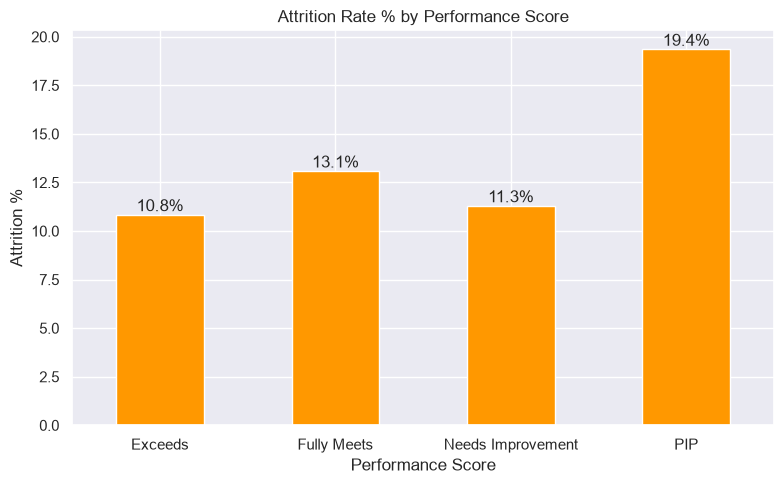

In [21]:
plt.figure(figsize=(8,5))
perf_attr = emp.groupby('Performance Score')['Attrition_Flag'].mean().reindex(perf_order) * 100
ax = perf_attr.plot(kind='bar', color='#FF9800')
ax.bar_label(ax.containers[0], fmt='%.1f%%')
plt.title('Attrition Rate % by Performance Score')
plt.xlabel('Performance Score')
plt.ylabel('Attrition %')
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig(os.path.join(CHART_DIR, '6_perf_attrition.png'))
plt.show()

### Engagement score

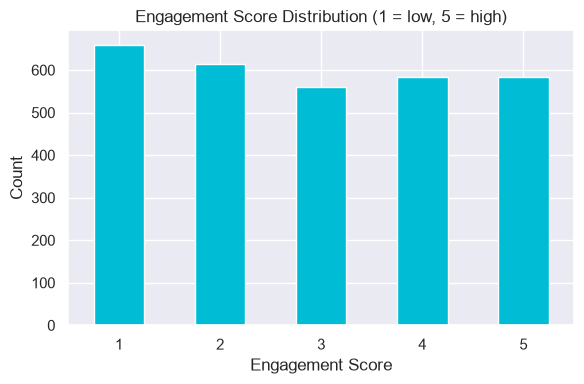

In [22]:
plt.figure(figsize=(6,4))
survey['Engagement Score'].value_counts().sort_index().plot(kind='bar', color='#00BCD4')
plt.title('Engagement Score Distribution (1 = low, 5 = high)')
plt.xlabel('Engagement Score')
plt.ylabel('Count')
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig(os.path.join(CHART_DIR, '7_engagement_dist.png'))
plt.show()

### Training outcome

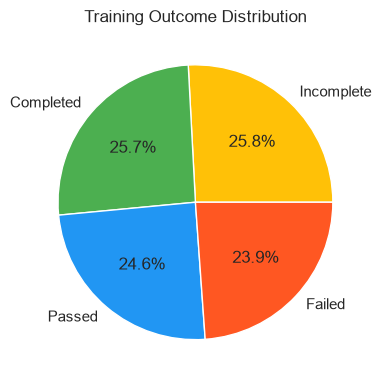

In [23]:
# there are 4 outcomes, the old version only had 3 colours so one slice repeated a colour
plt.figure(figsize=(6,4))
training['Training Outcome'].value_counts().plot(
    kind='pie', autopct='%1.1f%%',
    colors=['#FFC107', '#4CAF50', '#2196F3', '#FF5722'])
plt.title('Training Outcome Distribution')
plt.ylabel('')
plt.tight_layout()
plt.savefig(os.path.join(CHART_DIR, '8_training_outcome.png'))
plt.show()

### Recruitment status

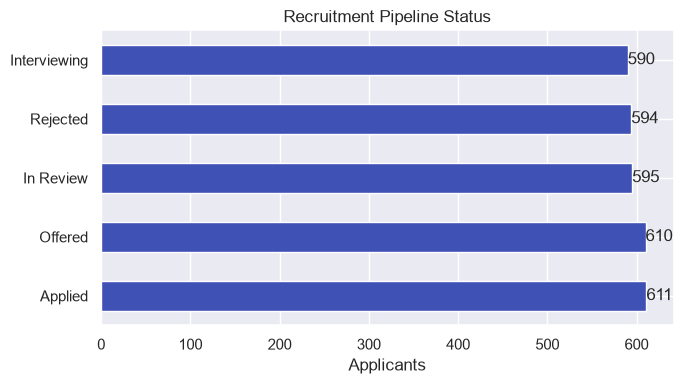

In [24]:
plt.figure(figsize=(7,4))
ax = recruit['Status'].value_counts().plot(kind='barh', color='#3F51B5')
ax.bar_label(ax.containers[0])
plt.title('Recruitment Pipeline Status')
plt.xlabel('Applicants')
plt.ylabel('')
plt.tight_layout()
plt.savefig(os.path.join(CHART_DIR, '9_recruitment_status.png'))
plt.show()

### Tenure vs attrition

             count  sum  mean
Tenure_Band                  
<1 yr          668  164  24.6
1-2 yrs        625  107  17.1
2-3 yrs        605   66  10.9
3-4 yrs        541   34   6.3
4+ yrs         561   16   2.9


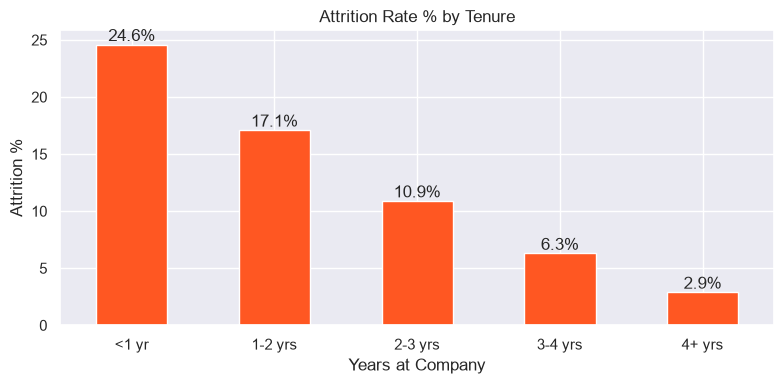

In [25]:
tenure_attr = emp.groupby('Tenure_Band')['Attrition_Flag'].agg(['count', 'sum', 'mean'])
tenure_attr['mean'] = (tenure_attr['mean'] * 100).round(1)
print(tenure_attr)

plt.figure(figsize=(8,4))
ax = tenure_attr['mean'].plot(kind='bar', color='#FF5722')
ax.bar_label(ax.containers[0], fmt='%.1f%%')
plt.title('Attrition Rate % by Tenure')
plt.xlabel('Years at Company')
plt.ylabel('Attrition %')
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig(os.path.join(CHART_DIR, '10_tenure_attrition.png'))
plt.show()

# Section 4 - What is driving attrition?
The charts above show *where* attrition is high. In this section I try to check *why* by comparing the people who left
with the people who stayed. I also use two simple statistical tests to see if a difference is real or could just be random:
- **t-test** for the survey scores (comparing two averages)
- **chi-square test** for training outcome (comparing two categorical columns)

If the p-value is below 0.05 I treat the difference as significant.

### 4.1 Survey scores: leavers vs stayers

In [26]:
score_cols = ['Engagement Score', 'Satisfaction Score', 'Work-Life Balance Score', 'Current Employee Rating']

df['Group'] = df['Attrition_Flag'].map({0: 'Stayed', 1: 'Left'})
score_means = df.groupby('Group')[score_cols].mean().round(2)
print(score_means)
print()

for col in score_cols:
    left = df[df['Attrition_Flag'] == 1][col]
    stayed = df[df['Attrition_Flag'] == 0][col]
    t_stat, p_value = ttest_ind(left, stayed)
    print(f"{col:26} p-value = {p_value:.3f}")

        Engagement Score  Satisfaction Score  Work-Life Balance Score  \
Group                                                                   
Left                2.90                3.12                      2.9   
Stayed              2.95                3.01                      3.0   

        Current Employee Rating  
Group                            
Left                       3.07  
Stayed                     2.95  

Engagement Score           p-value = 0.552
Satisfaction Score         p-value = 0.147
Work-Life Balance Score    p-value = 0.167
Current Employee Rating    p-value = 0.032


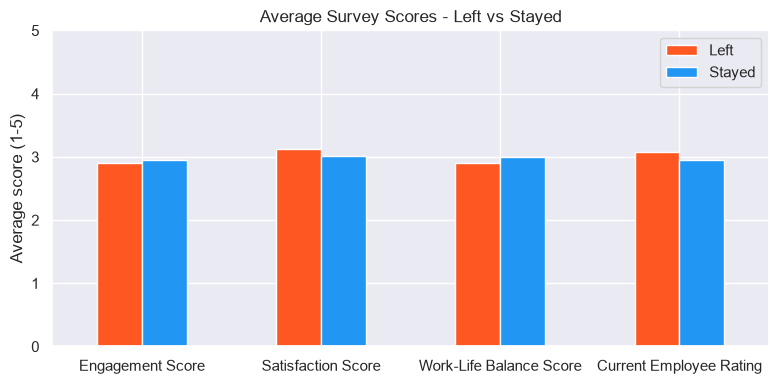

In [27]:
score_means.T.plot(kind='bar', figsize=(8,4), color=['#FF5722', '#2196F3'])
plt.title('Average Survey Scores - Left vs Stayed')
plt.ylabel('Average score (1-5)')
plt.ylim(0, 5)
plt.xticks(rotation=0)
plt.legend(title='')
plt.tight_layout()
plt.savefig(os.path.join(CHART_DIR, '11_survey_scores_attrition.png'))
plt.show()

### 4.2 Training outcome vs attrition

In [28]:
training_table = pd.crosstab(df['Training Outcome'], df['Attrition_Flag'])
training_table.columns = ['Stayed', 'Left']
training_table['Attrition %'] = (training_table['Left'] / training_table.sum(axis=1) * 100).round(1)
print(training_table)

chi2, p_value, dof, expected = chi2_contingency(pd.crosstab(df['Training Outcome'], df['Attrition_Flag']))
print('\nChi-square p-value:', round(p_value, 3))

                  Stayed  Left  Attrition %
Training Outcome                           
Completed            683    87         11.3
Failed               630    86         12.0
Incomplete           676    99         12.8
Passed               624   115         15.6

Chi-square p-value: 0.074


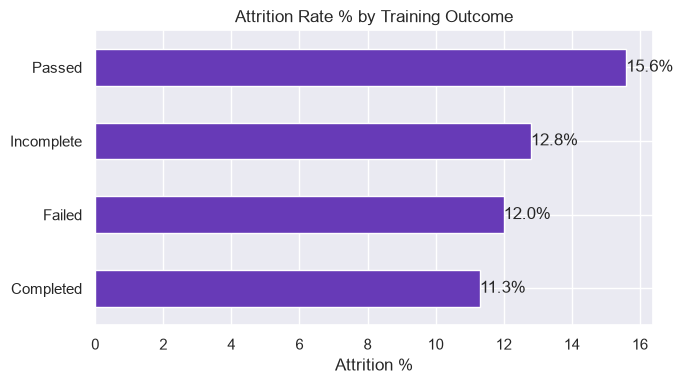

In [29]:
plt.figure(figsize=(7,4))
ax = training_table['Attrition %'].sort_values().plot(kind='barh', color='#673AB7')
ax.bar_label(ax.containers[0], fmt='%.1f%%')
plt.title('Attrition Rate % by Training Outcome')
plt.xlabel('Attrition %')
plt.ylabel('')
plt.tight_layout()
plt.savefig(os.path.join(CHART_DIR, '12_training_outcome_attrition.png'))
plt.show()

### 4.3 Job titles with the highest attrition
Only titles with at least 20 employees are included, otherwise a title with 2 people and 1 leaver shows 50%.

                          count  sum  mean
Title                                     
BI Developer                 44   12  27.3
Database Administrator       25    6  24.0
Production Technician II    516  119  23.1
Software Engineer            90   20  22.2
Production Manager          154   30  19.5
Sales Manager                30    4  13.3
Production Technician I    1321  176  13.3
Shared Services Manager      20    1   5.0


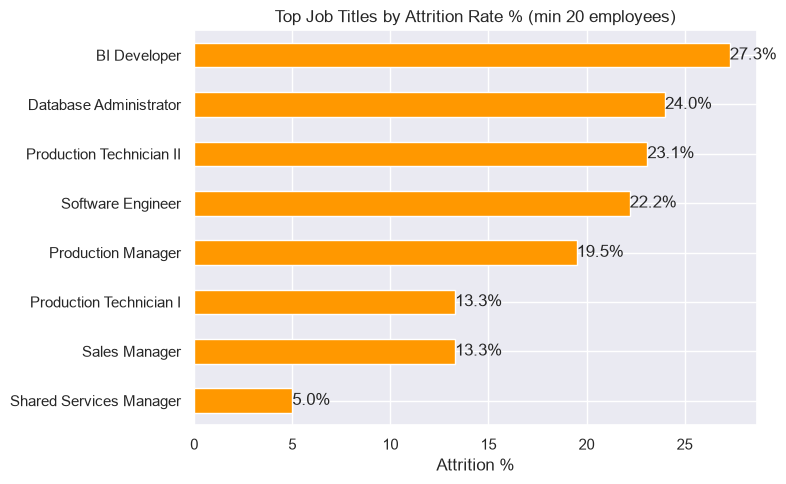

In [30]:
title_attr = emp.groupby('Title')['Attrition_Flag'].agg(['count', 'sum', 'mean'])
title_attr = title_attr[title_attr['count'] >= 20]
title_attr['mean'] = (title_attr['mean'] * 100).round(1)
top_titles = title_attr.sort_values('mean', ascending=False).head(8)
print(top_titles)

plt.figure(figsize=(8,5))
ax = top_titles['mean'].sort_values().plot(kind='barh', color='#FF9800')
ax.bar_label(ax.containers[0], fmt='%.1f%%')
plt.title('Top Job Titles by Attrition Rate % (min 20 employees)')
plt.xlabel('Attrition %')
plt.ylabel('')
plt.tight_layout()
plt.savefig(os.path.join(CHART_DIR, '13_job_title_attrition.png'))
plt.show()

### 4.4 Correlation between numeric columns

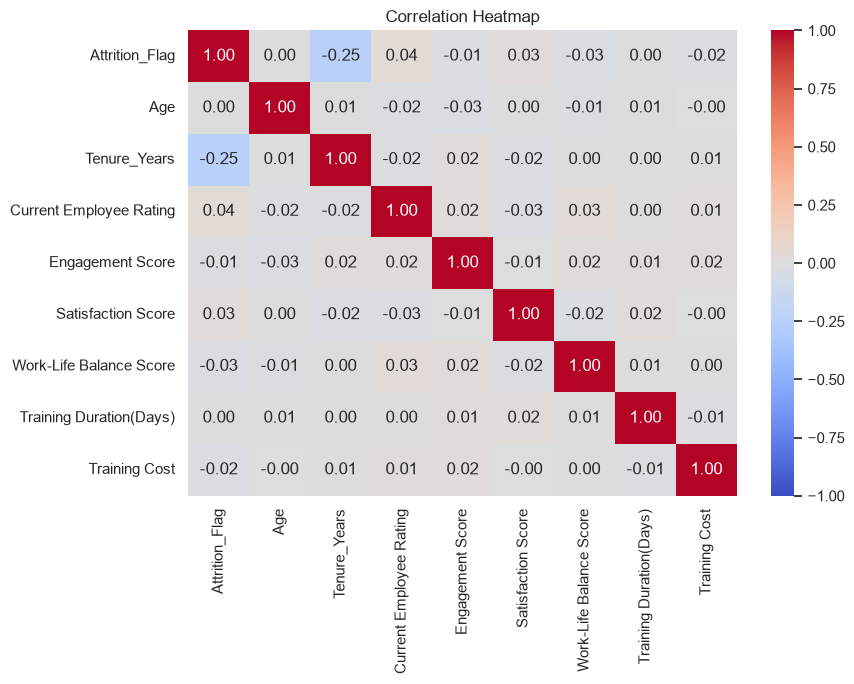

Tenure_Years              -0.246
Work-Life Balance Score   -0.025
Training Cost             -0.016
Engagement Score          -0.011
Age                        0.001
Training Duration(Days)    0.002
Satisfaction Score         0.026
Current Employee Rating    0.039
Name: Attrition_Flag, dtype: float64


In [31]:
num_cols = ['Attrition_Flag', 'Age', 'Tenure_Years', 'Current Employee Rating', 'Engagement Score',
            'Satisfaction Score', 'Work-Life Balance Score', 'Training Duration(Days)', 'Training Cost']

plt.figure(figsize=(9,7))
sns.heatmap(df[num_cols].corr(), annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Correlation Heatmap')
plt.tight_layout()
plt.savefig(os.path.join(CHART_DIR, '14_correlation_heatmap.png'))
plt.show()

print(df[num_cols].corr()['Attrition_Flag'].drop('Attrition_Flag').sort_values().round(3))

### 4.5 Hires vs exits per year

      Hires  Exits
Year              
2018    255      1
2019    598     15
2020    592     38
2021    600     65
2022    620    118
2023    335    150


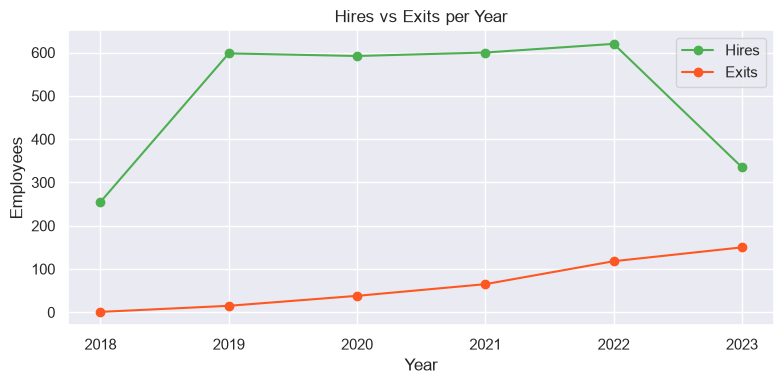

In [32]:
leavers = emp[emp['Attrition_Flag'] == 1]

hires = emp.groupby(emp['StartDate'].dt.year).size()
exits = leavers.groupby(leavers['ExitDate'].dt.year).size()

yearly = pd.DataFrame({'Hires': hires, 'Exits': exits}).fillna(0).astype(int)
yearly.index.name = 'Year'
print(yearly)

yearly.plot(kind='line', marker='o', figsize=(8,4), color=['#4CAF50', '#FF5722'])
plt.title('Hires vs Exits per Year')
plt.xlabel('Year')
plt.ylabel('Employees')
plt.xticks(yearly.index)
plt.tight_layout()
plt.savefig(os.path.join(CHART_DIR, '15_hires_vs_exits.png'))
plt.show()

### 4.6 Recruitment - offer rate by education level
This is the same idea as the *Offer Rate* measure in the dashboard.

                   applicants  offer_rate  avg_experience  avg_desired_salary
Education Level                                                              
Master's Degree           736        22.3            10.0             65481.7
Bachelor's Degree         785        20.0             9.9             65428.2
PhD                       741        20.0             9.9             64837.5
High School               738        19.1            10.0             64548.7


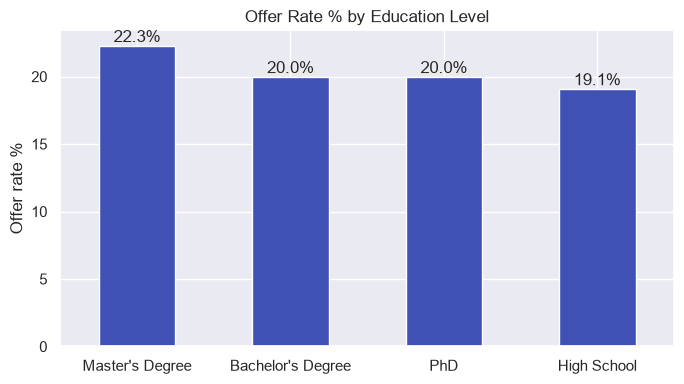

In [33]:
recruit['Offered'] = (recruit['Status'] == 'Offered').astype(int)

edu = recruit.groupby('Education Level').agg(
    applicants=('Applicant ID', 'count'),
    offer_rate=('Offered', 'mean'),
    avg_experience=('Years of Experience', 'mean'),
    avg_desired_salary=('Desired Salary', 'mean'))
edu['offer_rate'] = (edu['offer_rate'] * 100).round(1)
edu = edu.round(1).sort_values('offer_rate', ascending=False)
print(edu)

plt.figure(figsize=(7,4))
ax = edu['offer_rate'].plot(kind='bar', color='#3F51B5')
ax.bar_label(ax.containers[0], fmt='%.1f%%')
plt.title('Offer Rate % by Education Level')
plt.xlabel('')
plt.ylabel('Offer rate %')
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig(os.path.join(CHART_DIR, '16_offer_rate_education.png'))
plt.show()

recruit = recruit.drop(columns='Offered')

# Section 5 - Key Findings

**Overall**
- 387 out of 3000 employees left, so the attrition rate is **12.9%** (321 voluntary + 66 terminated for cause).
- Exits are going up every year: 15 in 2019, 65 in 2021, 118 in 2022 and already 150 in 2023 (data only goes till August 2023).

**Where attrition is high**
- **First year is the riskiest.** Attrition is 24.6% for employees with less than 1 year of tenure and drops to 2.9% after 4 years.
  (Part of this is because tenure stops counting when someone leaves, but the drop is still very clear.)
- **Production** (15.9%) and **Software Engineering** (17.4%) have the highest department rates. Production alone has 322 of the 387 leavers (83%), because it is the biggest department.
- By job title, **Production Technician II** (23.1%, 119 leavers) and **BI Developer** (27.3%, 12 of 44) stand out.
- Employees on a **PIP** leave the most (19.4%) compared to 10.8% for "Exceeds".
- Gender and age do not change much: female 13.9% vs male 11.6%, and every age group is between 11.5% and 14.4%.

**Things that did NOT explain attrition (this surprised me)**
- Engagement, satisfaction and work-life balance scores are almost the same for people who left and people who stayed (engagement 2.90 vs 2.95, p = 0.55). So in this data the survey would not work as an early warning signal.
- Training outcome is not significant either (chi-square p = 0.074). People who *passed* training actually left slightly more (15.6%) than people who completed it (11.3%).
- The only numeric column with a real correlation to attrition is tenure (-0.25).

**Recruitment**
- Offer rate is between 19% and 22% for every education level and the average desired salary is around $65k for all of them, so education level does not change much in this pipeline.

**What I would suggest to HR**
1. Put more effort into the first year (onboarding, buddy system, 3 and 6 month check-ins).
2. Look into Production Technician II roles and the BI / Software teams, where the rate is much higher than average.
3. Follow up properly with employees on a PIP.
4. The engagement survey is not picking up who will leave, so exit interviews could give better reasons.

**Limitations**
- This is a synthetic practice dataset, so some columns do not behave like real data (for example `TerminationType` is filled for active employees and 1146 active employees have an `ExitDate`).
- I only have one survey and one training record per employee, so I cannot see how scores changed over time.

# Section 6 - Load cleaned data into SQL Server (optional)
I used SQL Server Express + SSMS for the queries in `sql/hr_analytics.sql`.
Set `LOAD_TO_SQL = True` only if SQL Server is running on your machine (needs `sqlalchemy` and `pyodbc`).

In [34]:
# set this to True only when SQL Server Express is running locally
LOAD_TO_SQL = False

if LOAD_TO_SQL:
    from sqlalchemy import create_engine, types

    server = 'localhost\\SQLEXPRESS'
    database = 'hr_analytics'
    connection_string = f'mssql+pyodbc://{server}/{database}?driver=ODBC+Driver+17+for+SQL+Server&trusted_connection=yes'
    engine = create_engine(connection_string)

    date_cols = {
        'cleaned_hr_data.csv': ['StartDate', 'ExitDate', 'DOB', 'Survey Date', 'Training Date'],
        'cleaned_recruitment.csv': ['Application Date', 'Date of Birth'],
    }

    for file_name, table_name in [('cleaned_hr_data.csv', 'hr_data'), ('cleaned_recruitment.csv', 'recruitment_data')]:
        data = pd.read_csv(os.path.join(CLEAN_DIR, file_name), parse_dates=date_cols[file_name])

        # map pandas types to SQL types (dates as DATE so YEAR() / MONTH() work in SQL)
        sql_types = {}
        for col in data.columns:
            if pd.api.types.is_datetime64_any_dtype(data[col]):
                sql_types[col] = types.DATE()
            elif data[col].dtype == 'int64':
                sql_types[col] = types.INTEGER()
            elif data[col].dtype == 'float64':
                sql_types[col] = types.FLOAT()
            else:
                sql_types[col] = types.NVARCHAR(length=255)

        data.to_sql(table_name, con=engine, if_exists='replace', index=False, dtype=sql_types)
        print(f"'{table_name}' exported to {database} ({len(data)} rows)")
else:
    print('Skipping SQL Server upload (LOAD_TO_SQL = False)')

Skipping SQL Server upload (LOAD_TO_SQL = False)
